In [1]:
# Install packages from requirements.txt
# !pip install torchtuples
# !pip install pycox
# !pip install shap
# !pip install lifelines

In [2]:
# Load package
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Arial"
import pandas as pd
import seaborn as sns

from sklearn.model_selection import GridSearchCV
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.model_selection import KFold, StratifiedKFold
from sksurv.metrics import concordance_index_censored

import time
import torch
import torchtuples as tt

from pycox.models import CoxPH
from pycox.evaluation import EvalSurv

# BIoMOSurv
from BioMOSurv.preprocess import hybrid_selection, normalise_data, predict_omic

# Seed
import random
random.seed(1)     # python random generator
np.random.seed(1)  # numpy random generator

torch.manual_seed(1)
torch.cuda.manual_seed_all(1)

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.filterwarnings("ignore", category=np.VisibleDeprecationWarning)

sns.set_style("white")


In [3]:
# Step 1: Load data
path = '../Data/'
# map_id = pd.read_csv(path+'mapped_gene_hugo_id.csv')
clinic = pd.read_csv(path+'clinical_data.csv', index_col=0)
gene = pd.read_csv(path+'rna_seq_preprocessed.csv', index_col=0)
meta = pd.read_csv(path+'flux_preprocessed.csv', index_col=-1)


In [4]:
# Input hyperparameters
num_gene_kegg = 50   # Number of significant pathways selected from KEGG - optimal value is 100
num_gene_mrmr = 1500  #None # Select important genes ranked from mrmr, from None (select all), 1 to 3238

# Input for deep learning model
grid_params = {
    "batch_size": [350],
    "dropout": [ 0.3, 0.5], # 0.7
    "learning_rate": [0.0001, 0.001 ], #0.01
    "epochs": [100],
}
RANDOM_STATE = 42
n=1 # Number of run for each model
k=5 # Number of folds for cross-validation

# Select one mode: all for unimodal and late fusion; early for early fusion; intermediate for intermediate fusion
# mode_name = 'BioMOSurv_intermediate', 'BioMOSurv_early', 'BioMOSurv_all'
mode_name = 'BioMOSurv_all'

In [5]:
# Step 2: Preprocess data
# 2.1 Clean up gene data

# Check duplicate values
print('The number of duplicate values, missing values of clinic in data:', clinic.index.duplicated().sum(), clinic.isna().sum().sum())
print('The number of duplicate values, missing values of gene in data:', gene.index.duplicated().sum(),  gene.isna().sum().sum())
print('The number of duplicate values, missing values of flux in data:', meta.index.duplicated().sum(),  meta.isna().sum().sum())

# preprocess
df_clinic = clinic.drop([ 'ajcc_pathologic_tumor_stage', 'initial_pathologic_dx_year'], axis = 1)
gene.index = gene.index.str[:12]


df_clinic = pd.merge(df_clinic, gene[ 'Subtype_mRNA'],left_index=True, right_index=True, how='inner')

df_gene = gene.drop(['Subtype_mRNA'], axis=1)
df_meta = meta.copy()#meta.drop(['samplesID'], axis=1)
df_meta.index = df_meta.index.str[:12]

# # Exclude patient time and status =0
df_clinic = df_clinic.query('`OS.Status` !=0 | `OS.time` !=0')


The number of duplicate values, missing values of clinic in data: 0 0
The number of duplicate values, missing values of gene in data: 0 0
The number of duplicate values, missing values of flux in data: 0 0


In [6]:
# 2.2 Feature selection - Select KEGG pathway
# Hybrid feature selection: KEGG + mrmr 

df_gene = hybrid_selection(df_gene, num_gene_mrmr=num_gene_mrmr, num_gene_kegg=num_gene_kegg)

Total KEGG selected gene: 2158
Total combined selected gene: 3502


In [7]:
# Merge file to match samples

df = pd.merge(df_clinic, pd.merge(df_gene, df_meta, left_index=True, right_index=True, how='inner')
              , left_index=True, right_index=True, how='inner')
print('Data shape', df.shape)
print('The number of duplicate values in data:', df.index.duplicated().sum(), df.isna().sum().sum())
# df.to_csv('multimodal_processed_data.csv')
print(df.head(3))

Data shape (1017, 6479)
The number of duplicate values in data: 0 0
              OS.time   age  OS.Status  race  histological_type  tumor_status  \
TCGA-3C-AAAU   4047.0  55.0        0.0   3.0                2.0           1.0   
TCGA-3C-AALI   4005.0  50.0        0.0   2.0                1.0           0.0   
TCGA-3C-AALJ   1474.0  62.0        0.0   2.0                1.0           0.0   

              menopause_status  Subtype_mRNA    F13B   GPCPD1  ...  MAR13082  \
TCGA-3C-AAAU               2.0           0.0  0.0000  856.133  ...  0.052918   
TCGA-3C-AALI               4.0           2.0  3.2626  959.761  ...  0.052918   
TCGA-3C-AALJ               4.0           1.0  0.0000  897.552  ...  0.052918   

              MAR13086     MAR20016     MAR20020    MAR20044    MAR20045  \
TCGA-3C-AAAU  0.005948   959.342313  1000.000015  280.248364  280.248364   
TCGA-3C-AALI  0.005948  1000.000000  1000.000015  327.455337  327.455337   
TCGA-3C-AALJ  0.005948   602.761923  1000.000015  356.4026

In [8]:
# Prepare data
# y: time and event , X: for clinical, transcriptomic, metabolic features
X = df.drop(['OS.time','OS.Status'], axis=1)

# Split data into clinical, gene, metabolic dataframe
n_clinic =df_clinic.shape[1] -2
n_gene = df_gene.shape[1]
n_meta =  df_meta.shape[1] 

df_c = X.iloc[:,:n_clinic]
df_g = X.iloc[:, n_clinic: n_gene+n_clinic]
df_m = X.iloc[:,n_gene+n_clinic:]
# Overview of data after preprocessing
print(df_m.head(3))
print(df_g.head(3))
print(df_c.head(3))

print("Shape of clinical, gene, metabolic data:", df_c.shape, df_g.shape, df_m.shape)
# print('Shape', df_clinic.shape, df_g.shape, df_m.shape)

get_target = lambda df_clinic: (df_clinic['OS.time'].values, df_clinic['OS.Status'].values)

# X = np.asarray(X, dtype=np.float32)
X_clinic = np.asarray(df_c, dtype=np.float32)
X_gene = np.asarray(df_g, dtype=np.float32)
X_meta = np.asarray(df_m, dtype=np.float32)

y = df[['OS.Status','OS.time']].to_records(index=False)

              MAR00019  MAR00020_b     MAR00025     MAR00030     MAR00031  \
TCGA-3C-AAAU  0.000135      1000.0   888.410414   888.410414  3715.070614   
TCGA-3C-AALI  0.000135      1000.0  1487.350905  1487.350905  3221.198457   
TCGA-3C-AALJ  0.000135      1000.0  1189.600749  1189.600749  2589.102711   

                 MAR00032  MAR00038_b  MAR00038_f  MAR00040  MAR00054_f  ...  \
TCGA-3C-AAAU  3715.070614      1000.0      1000.0    1000.0  999.999364  ...   
TCGA-3C-AALI  3221.198457      1000.0      1000.0    1000.0  999.999364  ...   
TCGA-3C-AALJ  2589.102711      1000.0      1000.0    1000.0  999.999364  ...   

              MAR13082  MAR13086     MAR20016     MAR20020    MAR20044  \
TCGA-3C-AAAU  0.052918  0.005948   959.342313  1000.000015  280.248364   
TCGA-3C-AALI  0.052918  0.005948  1000.000000  1000.000015  327.455337   
TCGA-3C-AALJ  0.052918  0.005948   602.761923  1000.000015  356.402664   

                MAR20045  MAR20052    MAR20066    MAR20069     MAR20070  

In [9]:
# Function to prepare for NN model
# X should be dataframe --> after preprocessing to numpy
def split_data(X):
    clinic = X.iloc[:,:n_clinic]
    gene = X.iloc[:, n_clinic: n_gene+n_clinic]
    meta = X.iloc[:,n_gene+n_clinic:]
    return [clinic, gene, meta]


In [10]:
# Step 3: Model training and evaluation - Early and intermediate fusion
from BioMOSurv.unimodal import optimise_model
from BioMOSurv.fusion import  BC_Early_Wrap, Intermediate_Wrap

# grid_params = {
#     "batch_size": [350],
#     "dropout": [ 0.5, 0.7],
#     "learning_rate": [ 0.001],
#     "epochs": [50],
# }

inner_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Save variable
cindex_list= []

i=0
# n=1
np.random.seed(1)
seeds = np.random.permutation(1500)[:n]

if mode_name == 'BioMOSurv_early':
    print(mode_name)
    for s in seeds:
        print(s)
        cv_outer  = StratifiedKFold(n_splits=k,  shuffle=True, random_state=s)
        for train_ix, test_ix in cv_outer.split(X, y['OS.Status']):
            print('Run', i)
            i+=1
            # split data
            X_train, X_test = X.iloc[train_ix, :], X.iloc[test_ix, :]
            y_train, y_test = y[train_ix], y[test_ix]

            # Normalise
            X_train, X_test = normalise_data(X_train, X_test)
            
            ### ---------------- Early fusion model ----------------------------#
            start_c = time.time()
            print('Clinical results')
            model_early, cindex_early, best_param_early = optimise_model(model = BC_Early_Wrap(), para= grid_params,
                        inner_cv=inner_cv, X_train=X_train, y_train=y_train,
                        X_test=X_test, y_test=y_test)
            end_c = time.time()
            print(f'Time: {end_c - start_c}')
            cindex_list.append(cindex_early)
    
if mode_name == 'BioMOSurv_intermediate':
    feature_dims = (n_clinic, n_gene, n_meta)
    print(mode_name)
    for s in seeds:
        print(s)
        cv_outer  = StratifiedKFold(n_splits=5,  shuffle=True, random_state=s)
        for train_ix, test_ix in cv_outer.split(X, y['OS.Status']):
            print('Run', i)
            i+=1
            # split data
            X_train, X_test = X.iloc[train_ix, :], X.iloc[test_ix, :]
            y_train, y_test = y[train_ix], y[test_ix]

            # Normalise
            X_train, X_test = normalise_data(X_train, X_test)
            
            ### ---------------- Intermediate fusion model ----------------------------#
            start_c = time.time()
            print('Intermediate results')
            model_inter, cindex_inter, best_param_inter = optimise_model(model = Intermediate_Wrap(
                feature_dims=feature_dims), para= grid_params,
                        inner_cv=inner_cv, X_train=X_train, y_train=y_train,
                        X_test=X_test, y_test=y_test)
            end_c = time.time()
            print(f'Time: {end_c - start_c}')
            cindex_list.append(cindex_inter)


In [12]:
# Step 3: Model training and evaluation
from BioMOSurv.unimodal import Clinical_Wrap, Gene_Wrap, Meta_Wrap, optimise_model
from BioMOSurv.fusion import pairwise_fusion, late_fusion, hybrid_fusion

inner_cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# Save variable
cindex_list, pred_list =[], []
X_test_list, y_test_list =[], []
X_train_list =[]
mode_c_list, mode_g_list, mode_m_list = [], [], []
X_c_list, X_g_list, X_m_list = [], [], []

i=0
# n=1
np.random.seed(1)
seeds = np.random.permutation(1500)[:n]

if mode_name == 'BioMOSurv_all':
    print(mode_name)
    for s in seeds:
        print(s)
        cv_outer  = StratifiedKFold(n_splits=k,  shuffle=True, random_state=s)
        for train_ix, test_ix in cv_outer.split(X, y['OS.Status']):
            print('Run', i)
            i+=1
            # split data
            X_train, X_test = X.iloc[train_ix, :], X.iloc[test_ix, :]
            y_train, y_test = y[train_ix], y[test_ix]

            # Split to omic type
            X_train_c, X_train_g, X_train_m = split_data(X_train)
            X_test_c, X_test_g, X_test_m = split_data(X_test)

            # Normalise
            X_train_c, X_test_c = normalise_data(X_train_c, X_test_c)
            X_train_g, X_test_g= normalise_data(X_train_g, X_test_g)
            X_train_m, X_test_m = normalise_data(X_train_m, X_test_m)
            
            X_g_list.append([X_train_g, X_test_g])
            X_m_list.append([X_train_m, X_test_m])
            X_c_list.append([X_train_c, X_test_c])

            ### ---------------- Uni model ----------------------------#
            start_c = time.time()
            print('Clinical results')
            model_c, cindex_c, best_param_c = optimise_model(model = Clinical_Wrap(), para= grid_params,
                        inner_cv=inner_cv, X_train=X_train_c, y_train=y_train,
                        X_test=X_test_c, y_test=y_test)
            end_c = time.time()
            print(f'Time: {end_c - start_c}')
            print('Gene results')
            start_g = time.time()
            model_g, cindex_g, best_param_g = optimise_model(model = Gene_Wrap(n_gene=n_gene), para= grid_params,
                        inner_cv=inner_cv, X_train=X_train_g, y_train=y_train,
                        X_test=X_test_g, y_test=y_test)
            end_g = time.time()
            print(f'Time: {end_g - start_g}')
            print('Metabolic results')
            start_m = time.time()
            model_m, cindex_m, best_param_m = optimise_model(model = Meta_Wrap(n_meta=n_meta), para= grid_params,
                        inner_cv=inner_cv, X_train=X_train_m, y_train=y_train,
                        X_test=X_test_m, y_test=y_test)
            end_m = time.time()
            # Concatenate the result
            # Prediction of eachd data type:
            surv_c = model_c.predict(X_test_c)
            surv_g = model_g.predict(X_test_g)
            surv_m = model_m.predict(X_test_m)

            ###----------------- Pairwise integration --------------------#
            c_index_cg, surv_cg, c_index_cm, surv_cm, c_index_gm, surv_gm = pairwise_fusion(
            y_test, surv_c, surv_m, surv_g, cindex_c, cindex_m, cindex_g)
            # print("C-Index Clinical + Gene", c_index_cg)
            end_cg = time.time()

            ###----------------- Multimodal integration --------------------#
            # Late fusion
            c_index, surv = late_fusion(
                y_test, surv_c, surv_g, surv_m, cindex_c, cindex_g, cindex_m)

            # Hybrid fusion _ Clinical
            c_index1, surv1 = hybrid_fusion(
                y_test, surv_c, surv_gm, cindex_c, c_index_gm)
            print("C-Index Hybrid fusion with Clinical", c_index1)

            # Hybrid fusion _ Flux
            c_index2, surv2 = hybrid_fusion(
                y_test, surv_m, surv_cg, cindex_m, c_index_cg)
            print("C-Index Hybrid fusion with Metabolic", c_index2)

            # Hybrid fusion _ Gene
            c_index3, surv3 = hybrid_fusion(
                y_test, surv_g, surv_cm, cindex_g, c_index_cm)
            print("C-Index Hybrid fusion with Gene", c_index3)



            cindex_list.append([cindex_c, cindex_g, cindex_m, c_index_cg, c_index_cm, c_index_gm, c_index, c_index1, c_index2, c_index3])
            # cindex_list.append(cindex_c)
            pred_list.append([surv_c, surv_g, surv_m, surv_cg, surv_cm, surv_gm, surv, surv1, surv2, surv3])
            y_test_list.append(y_test)
            X_test_list.append(X_test)
            X_train_list.append(X_train)
            mode_c_list.append(model_c)
            mode_g_list.append(model_g)
            mode_m_list.append(model_m)



BioMOSurv_all
91
Run 0
Clinical results
Best parameter {'batch_size': 350, 'dropout': 0.3, 'epochs': 100, 'learning_rate': 0.001}
Test score 0.7847163420829806
Time: 6.356304407119751
Gene results
Best parameter {'batch_size': 350, 'dropout': 0.3, 'epochs': 100, 'learning_rate': 0.001}
Test score 0.7743437764606266
Time: 14.45146894454956
Metabolic results
Best parameter {'batch_size': 350, 'dropout': 0.3, 'epochs': 100, 'learning_rate': 0.001}
Test score 0.6363251481795089
C-Index Clinical + Gene 0.787
C-Index Clinical + Meta 0.7278
C-Index  Gene + Meta 0.7646
C-Index late fusion Clinical + Gene + Flux 0.7828
C-Index Hybrid fusion with Clinical 0.7955
C-Index Hybrid fusion with Metabolic 0.7722
C-Index Hybrid fusion with Gene 0.7786
Run 1
Clinical results
Best parameter {'batch_size': 350, 'dropout': 0.3, 'epochs': 100, 'learning_rate': 0.001}
Test score 0.7015873015873015
Time: 1.2969331741333008
Gene results
Best parameter {'batch_size': 350, 'dropout': 0.3, 'epochs': 100, 'learning

C              0.763686
G              0.763760
M              0.644521
C+G            0.777280
C+M            0.705580
G+M            0.765960
Late fusion    0.775800
Hybrid-F       0.784920
Hybrid_G       0.763940
Hybrid_C       0.776480
dtype: float64


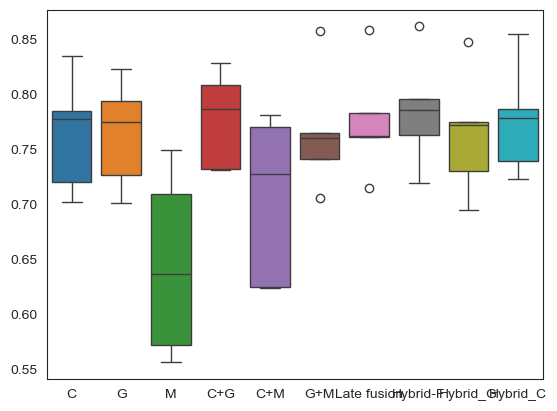

In [13]:
# Save 
name = ['C', 'G', 'M', 'C+G', 'C+M', 'G+M',  'Late fusion', 'Hybrid-F', 'Hybrid_G', 'Hybrid_C']
df_plot = pd.DataFrame(cindex_list, columns=name)
print(df_plot.mean())
# df.to_csv('Result/mrmr/cindex_late.csv', index=False)
sns.boxplot(data=df_plot)
plt.show()

In [ ]:
# Step 4: Posthoc analysis - KM curve
pd.options.mode.chained_assignment = None
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifelines.plotting import add_at_risk_counts
pd.options.mode.chained_assignment = None

# Top 30% and bottom 30% KM curve
fig, ax = plt.subplots(5,2,figsize=(9,20))
k=0
i=0
for pred in pred_list[i]:
    
    df_y = pd.DataFrame(y_test_list[i])
    df_y['score'] = pred
    # Filter 30% top and bot of time for the OS.status =0
    top = np.quantile(pred,0.7)
    bot = np.quantile(pred,0.3)
    print(f'70% Top value for LR {top}, 30% bottom for LR {bot}')
    hr = df_y.query('score >= @top')
    hr['Risk'] =1 
    lr = df_y.query('score < @bot')
    lr['Risk'] =0
    df_KM = pd.concat([lr, hr])

    # Convert to month
    df_KM['OS.time'] = round(df_KM['OS.time']/30,2)
    ix = df_KM['Risk'] == 1

    T_hr, E_hr = df_KM.loc[ix]['OS.time'], df_KM.loc[ix]['OS.Status']
    T_lr, E_lr = df_KM.loc[~ix]['OS.time'], df_KM.loc[~ix]['OS.Status']

    # Set-up plots
    k+=1
    # fig = plt.figure(figsize=(8, 14))
    plt.subplot(5,2,k)

    # Fit survival curves
    kmf_hr = KaplanMeierFitter()
    ax = kmf_hr.fit(T_hr, E_hr, label='HR', timeline=range(0, 220, 2)).plot_survival_function(color="#d9692f")

    kmf_lr = KaplanMeierFitter()
    ax = kmf_lr.fit(T_lr, E_lr, label='LR', timeline=range(0, 220, 2)).plot_survival_function(color="#2f98ad")

    add_at_risk_counts(kmf_hr, kmf_lr)
    # Format graph
    plt.ylim(0,1)
    ax.set_xlabel('Time(months)',fontsize='large')
    ax.set_ylabel('Est. probability of survival',fontsize='large')

    # Calculate p-value
    res = logrank_test(T_hr, T_lr, event_observed_A=E_hr, event_observed_B=E_lr, alpha=.95)
    # res.print_summary()

    # Locate the label at the 1st out of 9 tick marks
    xloc = max(np.max(T_hr),np.max(T_lr))/12
    ax.text(xloc,.1,'p-value = {:.3e}'.format(res.p_value),fontsize=9)
    ax.set_title('KM curve {}' .format(name[k-1]))
    ax.legend(loc='right')
    plt.tight_layout()

# plt.savefig('Result/KM_late_fusion.pdf',dpi=300)

In [ ]:
# Step 5: Interpret the predictions
import shap
shap.initjs()

k= 6
model_c_shap = mode_c_list[k]
model_g_shap = mode_g_list[k]
model_m_shap = mode_m_list[k]

# Interpret the late fusion model
def predict_latefusion(X):
    clinic = np.array(X[:,:n_clinic]).astype('float32')
    gene = np.array(X[:, n_clinic: n_gene+n_clinic]).astype('float32')
    meta = np.array(X[:,n_gene+n_clinic:]).astype('float32')

    preds1 = model_c_shap.predict(clinic)
    preds2 = model_g_shap.predict(gene)
    preds3 = model_m_shap.predict(meta)

    final_preds =np.average([preds1, preds2, preds3], weights=[cindex_c, cindex_g, cindex_m], axis=0)

    return final_preds
# Interpret the late fusion_F model
def predict_latefusion_F(X):

    clinic = np.array(X[:,:n_clinic]).astype('float32')
    gene = np.array(X[:, n_clinic: n_gene+n_clinic]).astype('float32')
    meta = np.array(X[:,n_gene+n_clinic:]).astype('float32')

    preds1 = model_c_shap.predict(clinic)
    preds2 = model_g_shap.predict(gene)
    preds3 = model_m_shap.predict(meta)
    pred_cg = np.average([preds1, preds2], weights=[cindex_c, cindex_g], axis=0)
    final_preds =np.average([pred_cg,preds3], weights=[c_index_cg, cindex_m], axis=0)
    
    return final_preds


cmap = sns.diverging_palette(220, 20,s=100, center="light", as_cmap=True)

clinical_sample = X_c_list[k][1]
gene_sample = X_g_list[k][1]
meta_sample = X_m_list[k][1]
sample_shap =np.concatenate([clinical_sample, gene_sample, meta_sample], axis=1)

train_shap_c = X_c_list[k][0][100:125,:]
train_shap_g = X_g_list[k][0][100:125,:]
train_shap_m = X_m_list[k][0][100:125,:]
train_shap = np.concatenate([train_shap_c, train_shap_g, train_shap_m], axis=1)
pd.DataFrame(sample_shap, columns=X.columns).to_csv(f'Result/SHAP/SHAP_Late_x_test_run_{k}.csv')

# Explainer
explainer = shap.Explainer(predict_latefusion, train_shap)
shap_values = explainer(sample_shap,  max_evals=20000)

# Save
df_shap_merged = pd.DataFrame(shap_values.values, columns= X_train.columns)
df_shap_merged.to_csv(f'Result/SHAP/shap_latefusion_{k}.csv', index=False)
# Plot
plt.gcf()
shap.summary_plot(shap_values.values, sample_shap, cmap = cmap, feature_names =X_train.columns)
shap.summary_plot(shap_values.values, sample_shap, cmap = cmap, show=False, feature_names=X_train.columns)
plt.savefig(f'Result/SHAP/SHAP_late_fusion_{k}.pdf', dpi=600, bbox_inches='tight')


In [ ]:
# Intepret Unimodal - best model in Gene
k=5
model_g_shap = mode_g_list[k]

def predict_gene(omic):
    preds = model_g_shap.predict(omic)

    return preds

# prepare test set
gene_sample = X_g_list[k][1]
train_shap = X_g_list[k][0][100:125,:]

pd.DataFrame(gene_sample, columns=df_g.columns).to_csv(f'SHAP_Gene_x_test_run_{k}.csv')


explainer_g = shap.KernelExplainer(predict_gene,  train_shap, feature_names=df_g.columns)
shap_values_g = explainer_g.shap_values(gene_sample)
plt.gcf()
shap.summary_plot(shap_values_g[0],  gene_sample, feature_names=df_g.columns, cmap = cmap, show=False)
plt.savefig(f'Result/SHAP/SHAP_gene_{k}.pdf', dpi=600, bbox_inches='tight')

shap_df_gene = pd.DataFrame(shap_values_g[0], columns= df_g.columns)
shap_df_gene.to_csv(f'Result/SHAP/shap_gene{k}.csv', index=False)

In [ ]:
# Intepret Unimodal - best model in Fluxomic data
k=4
model_m_shap = mode_m_list[k]

def predict_flux(omic):
    preds = model_m_shap.predict(omic)

    return preds

# prepare test set
flux_sample = X_m_list[k][1]
train_shap = X_m_list[k][0][100:125,:]
pd.DataFrame(flux_sample, columns=df_m.columns).to_csv(f'SHAP_Flux_x_test_run_{k}.csv')


explainer_m = shap.KernelExplainer(predict_flux,  train_shap, feature_names=df_m.columns)
shap_values_m = explainer_m.shap_values(flux_sample)

plt.gcf()
shap.summary_plot(shap_values_m[0],  flux_sample, feature_names=df_m.columns, cmap=cmap, show=False)
plt.savefig(f'Result/SHAP/SHAP_meta_{k}.pdf', dpi=600, bbox_inches='tight')

# Save
shap_df_meta = pd.DataFrame(shap_values_m[0], columns= df_m.columns)
shap_df_meta.to_csv(f'Result/SHAP/shap_meta_{k}.csv', index=False)

In [ ]:
# Intepret Unimodal - best model in Clinical data
k =6
model_c_shap = mode_c_list[k]

def predict_clinic(clinic):
    preds = model_c_shap.predict(clinic)
    return preds

# prepare test set
clinic_sample = X_c_list[k][1]
train_shap = X_c_list[k][0][100:125,:]

explainer_c = shap.KernelExplainer(predict_clinic,  train_shap, feature_names=df_clinic.columns)

plt.gcf()
shap_values_c = explainer_c.shap_values(clinic_sample)
shap.summary_plot(shap_values_c[0],  clinic_sample, feature_names=df_clinic.columns, cmap = cmap, show=False)
plt.savefig('Result/SHAP/SHAP_clinical.pdf', dpi=600, bbox_inches='tight')
pd.DataFrame(shap_values_c[0], columns= df_clinic.columns).to_csv('Result/SHAP/shap_clinical.csv', index=False)